**INST414 — Module 3 assignment | 2025 NYC 311 service requests**

In [5]:
# loading data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# counts contain commas in the exported CSV
df = pd.read_csv(
    "311_Service_Requests_from_2020_to_Present_20261030.csv",
    thousands=","
)

df.head()

,Community Board,Problem (formerly Complaint Type),count_unique_key
0,06 QUEENS,Street Sign - Damaged,87
1,13 QUEENS,Indoor Sewage,8
2,13 QUEENS,Standing Water,36
3,13 BROOKLYN,Real Time Enforcement,68
4,16 BROOKLYN,Noise - Street/Sidewalk,2246


In [7]:
# inspecting data
print("Rows, columns:", df.shape)
print("Column names:", df.columns.tolist())
print("Data types:\n", df.dtypes)
print("Missing values:\n", df.isna().sum())

print("Duplicate board-problem pairs:",
      df.duplicated(subset=[
          "Community Board",
          "Problem (formerly Complaint Type)"
      ]).sum())

print("Total 311 requests represented:", df["count_unique_key"].sum())
print("Distinct board labels:", df["Community Board"].nunique())
print("Distinct problem labels:", df["Problem (formerly Complaint Type)"].nunique())

assert pd.api.types.is_numeric_dtype(df["count_unique_key"])
assert (df["count_unique_key"] >= 0).all()
assert df["count_unique_key"].sum() == 3500650
assert not df.duplicated(
    subset=["Community Board", "Problem (formerly Complaint Type)"]
).any()

Rows, columns: (9084, 3)
Column names: ['Community Board', 'Problem (formerly Complaint Type)', 'count_unique_key']
Data types:
 Community Board                      object
Problem (formerly Complaint Type)    object
count_unique_key                      int64
dtype: object
Missing values:
 Community Board                      0
Problem (formerly Complaint Type)    0
count_unique_key                     0
dtype: int64
Duplicate board-problem pairs: 0
Total 311 requests represented: 3500650
Distinct board labels: 77
Distinct problem labels: 183


Most reported complaint types:
 Problem (formerly Complaint Type)
Illegal Parking             577142
Noise - Residential         463233
HEAT/HOT WATER              311266
Noise - Street/Sidewalk     173028
Blocked Driveway            172653
UNSANITARY CONDITION        108819
Water System                 75460
Abandoned Vehicle            67893
Street Condition             66556
PLUMBING                     64639
Noise - Commercial           63935
Dirty Condition              59727
PAINT/PLASTER                55834
Noise                        55176
Traffic Signal Condition     47837
Encampment                   47579
Noise - Vehicle              43216
Derelict Vehicles            43053
Missed Collection            42936
DOOR/WINDOW                  41345
Name: count_unique_key, dtype: int64

Least reported complaint types:
 Problem (formerly Complaint Type)
Building Condition         5
X-Ray Machine/Equipment    4
DEP Highway Condition      4
Tanning                    4
Leaning Bar  

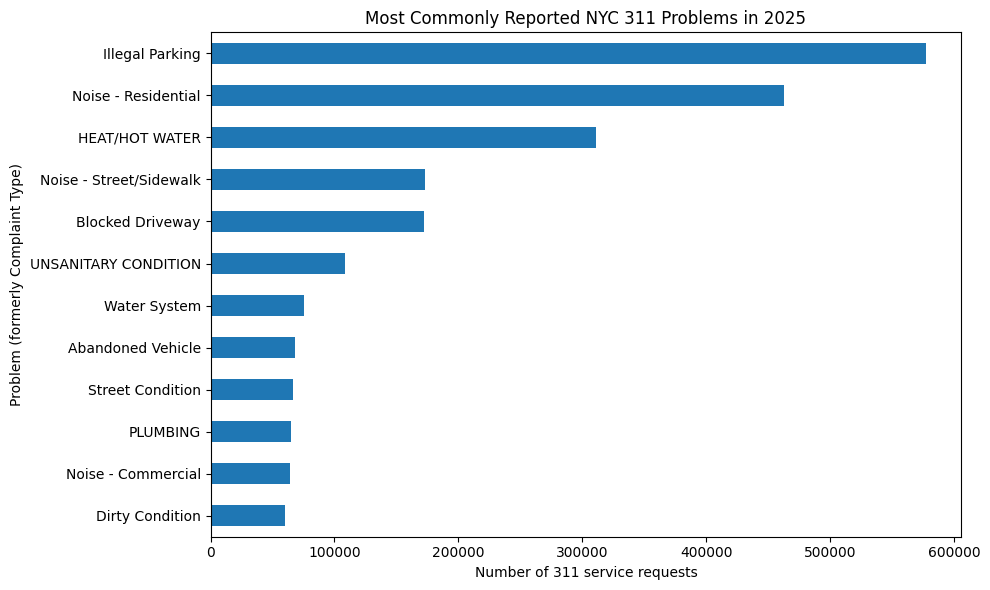

In [8]:
# examining complaint frequencies
problem_col = "Problem (formerly Complaint Type)"
board_col = "Community Board"
count_col = "count_unique_key"

problem_totals = (
    df.groupby(problem_col)[count_col]
    .sum()
    .sort_values(ascending=False)
)

print("Most reported complaint types:\n", problem_totals.head(20))
print("\nLeast reported complaint types:\n", problem_totals.tail(10))

# top 12 complaint types
plt.figure(figsize=(10, 6))

problem_totals.head(12).sort_values().plot(kind="barh")

plt.xlabel("Number of 311 service requests")
plt.title("Most Commonly Reported NYC 311 Problems in 2025")
plt.tight_layout()

plt.savefig("figure1_top_complaints.png", dpi=160)
plt.show()

In [9]:
# keeping the 59 regular Community Boards
max_board = {
    "MANHATTAN": 12,
    "BRONX": 12,
    "BROOKLYN": 18,
    "QUEENS": 14,
    "STATEN ISLAND": 3
}

valid_boards = []

for borough, max_number in max_board.items():
    for number in range(1, max_number + 1):
        valid_boards.append(f"{number:02d} {borough}")

print("Number of regular Community Board labels:", len(valid_boards))
print("Unmatched labels:\n",
      sorted(set(df[board_col]) - set(valid_boards)))

excluded = df[~df[board_col].isin(valid_boards)]

clean_df = df[df[board_col].isin(valid_boards)].copy()

print("Excluded requests:", excluded[count_col].sum())
print("Excluded percentage:",
      round(100 * excluded[count_col].sum() / df[count_col].sum(), 2))

print("Requests in regular boards:", clean_df[count_col].sum())
print("Number of regular boards:", clean_df[board_col].nunique())

assert clean_df[board_col].nunique() == 59
assert clean_df[count_col].sum() + excluded[count_col].sum() == df[count_col].sum()

Number of regular Community Board labels: 59
Unmatched labels:
 ['0 Unspecified', '26 BRONX', '27 BRONX', '28 BRONX', '55 BROOKLYN', '56 BROOKLYN', '64 MANHATTAN', '80 QUEENS', '81 QUEENS', '82 QUEENS', '83 QUEENS', '84 QUEENS', '95 STATEN ISLAND', 'Unspecified BRONX', 'Unspecified BROOKLYN', 'Unspecified MANHATTAN', 'Unspecified QUEENS', 'Unspecified STATEN ISLAND']
Excluded requests: 51152
Excluded percentage: 1.46
Requests in regular boards: 3449498
Number of regular boards: 59


In [10]:
# inspecting request totals by Community Board
board_totals = (
    clean_df.groupby(board_col)[count_col]
    .sum()
    .sort_values(ascending=False)
)

print("Highest-volume boards:\n", board_totals.head(10))
print("\nLowest-volume boards:\n", board_totals.tail(10))

Highest-volume boards:
 Community Board
12 BRONX        197234
12 MANHATTAN    109401
04 BRONX         88018
01 BROOKLYN      86732
05 BROOKLYN      82564
01 QUEENS        81090
12 QUEENS        79512
10 MANHATTAN     79485
07 BRONX         77909
05 QUEENS        77692
Name: count_unique_key, dtype: int64

Lowest-volume boards:
 Community Board
03 STATEN ISLAND    39079
06 QUEENS           35481
06 MANHATTAN        34186
16 BROOKLYN         33718
14 QUEENS           33716
02 STATEN ISLAND    33491
01 MANHATTAN        32878
11 QUEENS           30692
13 BROOKLYN         29091
02 BRONX            26681
Name: count_unique_key, dtype: int64


In [11]:
# grouping complaint types into broader categories
themes = {
    "Noise": [
        "Noise - Residential", "Noise - Street/Sidewalk",
        "Noise - Commercial", "Noise", "Noise - Vehicle",
        "Noise - Park", "Noise - House of Worship",
        "Noise - Helicopter", "Illegal Fireworks"
    ],

    "Housing/buildings": [
        "HEAT/HOT WATER", "UNSANITARY CONDITION", "PLUMBING",
        "PAINT/PLASTER", "DOOR/WINDOW", "WATER LEAK",
        "General Construction/Plumbing", "GENERAL", "ELECTRIC",
        "FLOORING/STAIRS", "APPLIANCE", "Elevator", "ELEVATOR",
        "Lead", "SAFETY", "Building/Use", "Boilers", "Plumbing",
        "Electrical", "OUTSIDE BUILDING", "Non-Residential Heat",
        "Mold", "Indoor Air Quality", "Indoor Sewage",
        "Window Guard", "Building Condition",
        "Building Drinking Water Tank", "Scaffold Safety",
        "Cranes and Derricks", "Construction Safety Enforcement"
    ],

    "Sanitation/pests": [
        "Dirty Condition", "Missed Collection", "Illegal Dumping",
        "Rodent", "Residential Disposal Complaint", "Dead Animal",
        "Street Sweeping Complaint", "Litter Basket Request",
        "Litter Basket Complaint", "Dumpster Complaint",
        "Unsanitary Animal Pvt Property",
        "Unsanitary Pigeon Condition",
        "Commercial Disposal Complaint",
        "Institution Disposal Complaint", "Industrial Waste",
        "Standing Water", "Mosquitoes",
        "Unsanitary Animal Facility",
        "Transfer Station Complaint",
        "Recycling Basket Complaint",
        "Sanitation Worker or Vehicle Complaint",
        "Urinating in Public"
    ],

    "Transportation/parking": [
        "Illegal Parking", "Blocked Driveway", "Abandoned Vehicle",
        "Derelict Vehicles", "Traffic", "Broken Parking Meter",
        "For Hire Vehicle Complaint", "Taxi Complaint",
        "Green Taxi Complaint", "Bike/Roller/Skate Chronic",
        "Bike/Roller/Skate", "Abandoned Bike", "E-Scooter",
        "Bike Rack", "Bus Stop Shelter Complaint",
        "Bus Stop Shelter Placement",
        "Municipal Parking Facility", "Taxi Licensee Complaint"
    ],

    "Streets/infrastructure": [
        "Water System", "Street Condition",
        "Traffic Signal Condition", "Street Light Condition",
        "Sidewalk Condition", "Sewer", "Damaged Tree",
        "Snow or Ice", "Curb Condition",
        "Overgrown Tree/Branches", "Dead/Dying Tree",
        "Street Sign - Damaged",
        "Root/Sewer/Sidewalk Condition",
        "Street Sign - Dangling", "Street Sign - Missing",
        "Highway Condition", "Water Conservation",
        "New Tree Request", "Illegal Tree Damage",
        "Wood Pile Remaining", "Water Quality",
        "Lot Condition", "Water Maintenance",
        "Sewer Maintenance", "DEP Street Condition",
        "DEP Highway Condition", "DEP Sidewalk Condition",
        "Highway Sign - Damaged", "Highway Sign - Missing",
        "Highway Sign - Dangling", "Bridge Condition",
        "Tunnel Condition", "Uprooted Stump"
    ]
}

# mapping each complaint type to one category
problem_to_theme = {}

for theme, problems in themes.items():
    for problem in problems:
        assert problem not in problem_to_theme
        problem_to_theme[problem] = theme

print("Unmatched mapping labels:",
      sorted(set(problem_to_theme) - set(clean_df[problem_col])))

assert set(problem_to_theme).issubset(set(df[problem_col]))

clean_df["theme"] = (
    clean_df[problem_col]
    .map(problem_to_theme)
    .fillna("Other")
)

# saving category classifications
category_audit = (
    clean_df.groupby([problem_col, "theme"])[count_col]
    .sum()
    .reset_index()
    .sort_values(count_col, ascending=False)
)

category_audit.to_csv("complaint_category_audit.csv", index=False)

category_audit.head(25)

Unmatched mapping labels: ['Bridge Condition', 'DEP Highway Condition', 'Highway Condition', 'Highway Sign - Damaged', 'Highway Sign - Dangling', 'Highway Sign - Missing', 'Municipal Parking Facility', 'Tunnel Condition']


,Problem (formerly Complaint Type),theme,count_unique_key
72,Illegal Parking,Transportation/parking,573439
100,Noise - Residential,Noise,462463
64,HEAT/HOT WATER,Housing/buildings,311236
16,Blocked Driveway,Transportation/parking,172405
101,Noise - Street/Sidewalk,Noise,171301
154,UNSANITARY CONDITION,Housing/buildings,108812
168,Water System,Streets/infrastructure,75398
4,Abandoned Vehicle,Transportation/parking,67174
111,PLUMBING,Housing/buildings,64634
140,Street Condition,Streets/infrastructure,63770


Theme totals:
 theme
Transportation/parking    887001
Housing/buildings         835402
Noise                     820064
Streets/infrastructure    357709
Other                     324888
Sanitation/pests          224434
Name: count_unique_key, dtype: int64

Theme percentages:
 theme
Transportation/parking    25.71
Housing/buildings         24.22
Noise                     23.77
Streets/infrastructure    10.37
Other                      9.42
Sanitation/pests           6.51
Name: count_unique_key, dtype: float64

Unclassified complaint types: 69

Most common complaints classified as Other:
Problem (formerly Complaint Type)
Encampment                     43643
Vendor Enforcement             28936
Drug Activity                  27950
Homeless Person Assistance     26851
Non-Emergency Police Matter    24480
Obstruction                    19093
Graffiti                       17614
Consumer Complaint             17133
Maintenance or Facility        17022
Food Establishment             10867
Ani

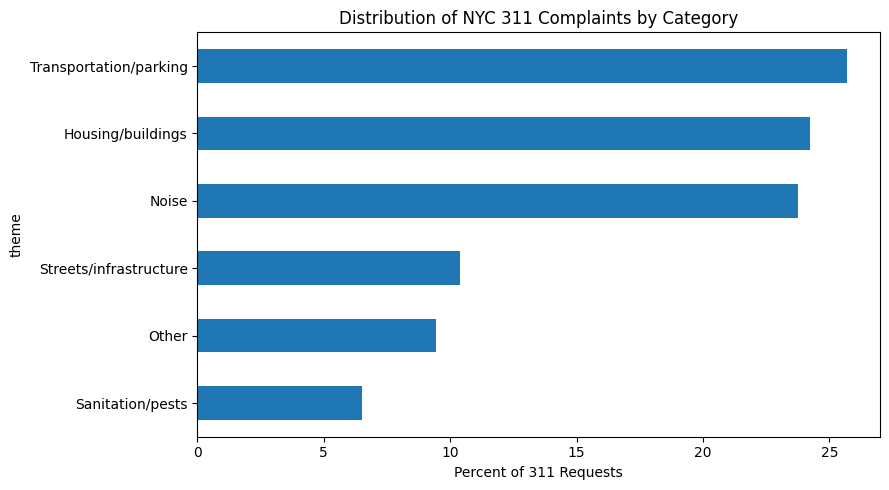

In [12]:
# checking category coverage
theme_totals = (
    clean_df.groupby("theme")[count_col]
    .sum()
    .sort_values(ascending=False)
)

print("Theme totals:\n", theme_totals)

print("\nTheme percentages:\n",
      (100 * theme_totals / theme_totals.sum()).round(2))

print("\nUnclassified complaint types:",
      clean_df.loc[
          clean_df["theme"] == "Other", problem_col
      ].nunique())

print("\nMost common complaints classified as Other:")

print(
    clean_df.loc[clean_df["theme"] == "Other"]
    .groupby(problem_col)[count_col]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

assert theme_totals.sum() == clean_df[count_col].sum()

# plotting complaint category distribution
plt.figure(figsize=(9, 5))

(100 * theme_totals / theme_totals.sum()).sort_values().plot(
    kind="barh"
)

plt.xlabel("Percent of 311 Requests")
plt.title("Distribution of NYC 311 Complaints by Category")
plt.tight_layout()

plt.savefig("figure2_theme_distribution.png", dpi=160)
plt.show()

In [13]:
# creating the Community Board feature matrix
theme_counts = (
    clean_df.groupby([board_col, "theme"])[count_col]
    .sum()
    .unstack(fill_value=0)
)

feature_names = [
    "Noise",
    "Housing/buildings",
    "Sanitation/pests",
    "Transportation/parking",
    "Streets/infrastructure",
    "Other"
]

theme_counts = theme_counts.reindex(
    columns=feature_names,
    fill_value=0
)

# converting request counts into proportions
board_totals = theme_counts.sum(axis=1)

feature_df = theme_counts.div(board_totals, axis=0)
feature_df.index.name = "Community Board"

print("Feature matrix shape:", feature_df.shape)
print(feature_df.head().round(3))
print("Row sums:", feature_df.sum(axis=1).round(8).unique())
print("Missing values:", feature_df.isna().sum().sum())

assert feature_df.shape == (59, 6)
assert np.allclose(feature_df.sum(axis=1), 1)
assert not feature_df.isna().any().any()
assert (feature_df >= 0).all().all()

feature_df.to_csv("community_board_features_2025.csv")

Feature matrix shape: (59, 6)
theme             Noise  Housing/buildings  Sanitation/pests  \
Community Board                                                
01 BRONX          0.241              0.397             0.057   
01 BROOKLYN       0.263              0.136             0.082   
01 MANHATTAN      0.198              0.052             0.039   
01 QUEENS         0.211              0.138             0.077   
01 STATEN ISLAND  0.160              0.194             0.130   

theme             Transportation/parking  Streets/infrastructure  Other  
Community Board                                                          
01 BRONX                           0.151                   0.080  0.073  
01 BROOKLYN                        0.283                   0.101  0.134  
01 MANHATTAN                       0.202                   0.091  0.418  
01 QUEENS                          0.380                   0.117  0.076  
01 STATEN ISLAND                   0.241                   0.210  0.064  
Row

    k   inertia
0   2  1.802173
1   3  1.156839
2   4  0.921228
3   5  0.719780
4   6  0.581032
5   7  0.471931
6   8  0.385127
7   9  0.349951
8  10  0.310747


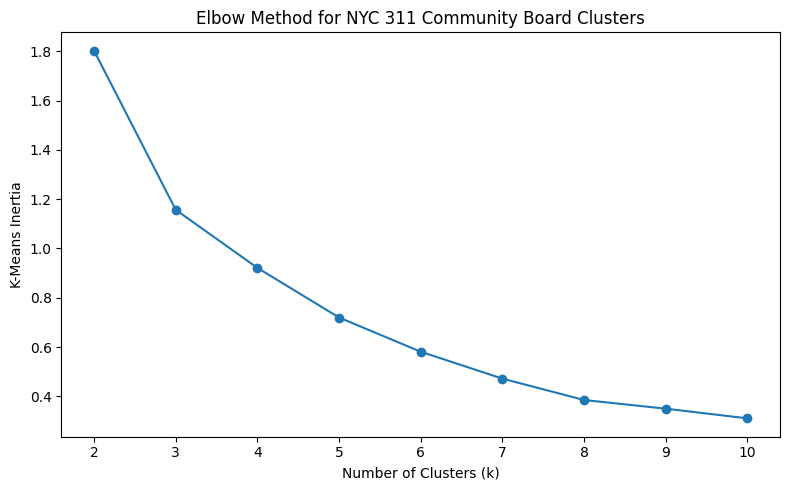

In [14]:
# comparing different values of k
k_values = range(2, 11)
inertias = []

for k in k_values:
    candidate_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    candidate_model.fit(feature_df)
    inertias.append(candidate_model.inertia_)

k_table = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias
})

print(k_table)

# elbow plot
plt.figure(figsize=(8, 5))

plt.plot(
    k_table["k"],
    k_table["inertia"],
    marker="o"
)

plt.xticks(list(k_values))
plt.xlabel("Number of Clusters (k)")
plt.ylabel("K-Means Inertia")
plt.title("Elbow Method for NYC 311 Community Board Clusters")
plt.tight_layout()

plt.savefig("figure3_elbow.png", dpi=160)
plt.show()

In [15]:
# examining cluster sizes for different k values
for k in [3, 4, 5]:

    test_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    test_model.fit(feature_df)

    print(
        "k =", k,
        "cluster sizes:",
        sorted(pd.Series(test_model.labels_).value_counts().tolist())
    )

k = 3 cluster sizes: [9, 22, 28]
k = 4 cluster sizes: [1, 11, 19, 28]
k = 5 cluster sizes: [1, 6, 15, 18, 19]


In [16]:
# k-means clustering
k = 3

cluster_model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

cluster_model.fit(feature_df)

cluster_labels = cluster_model.predict(feature_df)

cluster_df = pd.DataFrame(
    cluster_labels,
    index=feature_df.index,
    columns=["cluster"]
)

print("Cluster sizes:\n",
      cluster_df["cluster"].value_counts().sort_index())

assert cluster_df.shape[0] == 59
assert cluster_df["cluster"].nunique() == k

Cluster sizes:
 0    28
1    22
2     9
Name: cluster, dtype: int64


In [17]:
# examining cluster characteristics
results = feature_df.join(cluster_df)

cluster_profiles = (
    results.groupby("cluster")[feature_names]
    .mean() * 100
)

cluster_profiles = cluster_profiles.round(2)

print("Average complaint percentages by cluster:\n")
print(cluster_profiles.to_string())

# identifying example Community Boards
for cluster, boards in cluster_df.groupby("cluster"):

    print("\nCluster:", cluster)
    print("Size:", boards.shape[0])

    print(
        "Example Community Boards:",
        ", ".join(boards.index[:5])
    )

    top_themes = (
        cluster_profiles.loc[cluster]
        .sort_values(ascending=False)
        .head(3)
    )

    print("Top complaint categories:", top_themes.to_dict())

results.to_csv("community_board_cluster_assignments.csv")
cluster_profiles.to_csv("cluster_profiles_percent.csv")

Average complaint percentages by cluster:

         Noise  Housing/buildings  Sanitation/pests  Transportation/parking  Streets/infrastructure  Other
cluster                                                                                                   
0        16.68              15.88              7.93                   37.19                   14.91   7.41
1        27.42              38.08              5.73                   15.35                    7.47   5.95
2        22.46              14.61              6.25                   17.79                    8.90  29.99

Cluster: 0
Size: 28
Example Community Boards: 01 BROOKLYN, 01 QUEENS, 01 STATEN ISLAND, 02 BROOKLYN, 02 QUEENS
Top complaint categories: {'Transportation/parking': 37.19, 'Noise': 16.68, 'Housing/buildings': 15.88}

Cluster: 1
Size: 22
Example Community Boards: 01 BRONX, 02 BRONX, 03 BRONX, 03 BROOKLYN, 04 BRONX
Top complaint categories: {'Housing/buildings': 38.08, 'Noise': 27.42, 'Transportation/parking': 15.35}

Cl

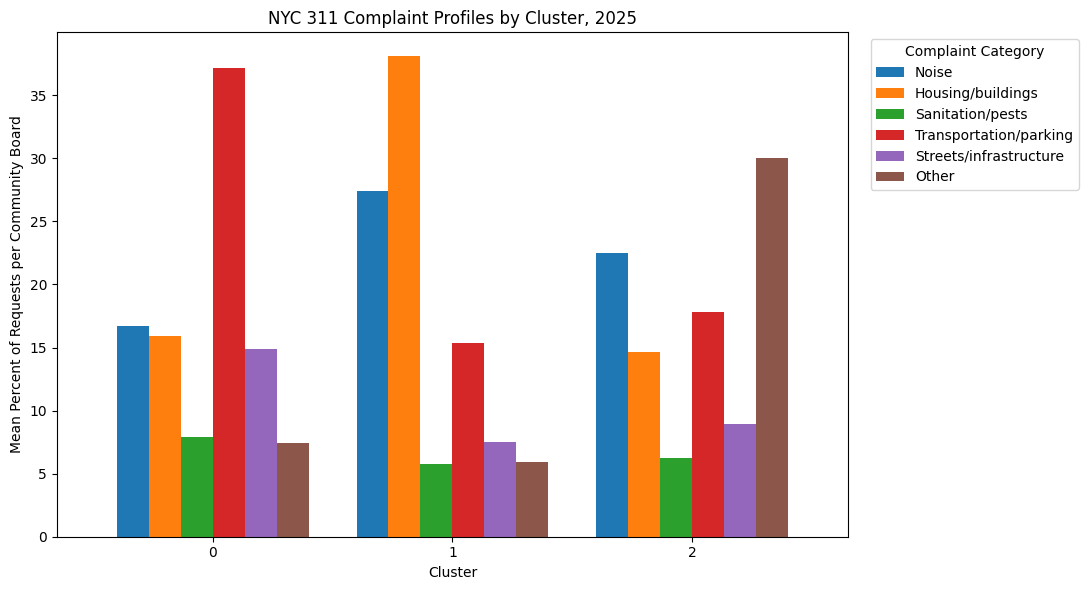

In [18]:
# comparing complaint categories across clusters
ax = cluster_profiles.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Mean Percent of Requests per Community Board")
ax.set_title("NYC 311 Complaint Profiles by Cluster, 2025")

plt.xticks(rotation=0)

plt.legend(
    title="Complaint Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "figure4_cluster_profiles.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [19]:
# validating clustering results
from sklearn.metrics import adjusted_rand_score

print(
    "All grouped requests preserved:",
    theme_counts.values.sum() == clean_df[count_col].sum()
)

print(
    "All boards assigned once:",
    results.index.is_unique and len(results) == 59
)

print(
    "Smallest cluster:",
    cluster_df["cluster"].value_counts().min()
)

# checking stability across random seeds
for seed in [0, 1, 7, 21, 99]:

    alternative = KMeans(
        n_clusters=k,
        random_state=seed,
        n_init=10
    )

    alternative.fit(feature_df)

    print(
        "Seed:", seed,
        "ARI:",
        round(adjusted_rand_score(
            cluster_labels,
            alternative.labels_
        ), 3)
    )

# identifying unusual Community Board profiles
distances = np.linalg.norm(
    feature_df.to_numpy() -
    cluster_model.cluster_centers_[cluster_labels],
    axis=1
)

distance_df = pd.DataFrame({
    "Community Board": feature_df.index,
    "cluster": cluster_labels,
    "distance_to_centroid": distances
})

print("\nMost unusual Community Board profiles:")

print(
    distance_df.sort_values(
        "distance_to_centroid",
        ascending=False
    ).head(10)
)

distance_df.to_csv("board_distance_validation.csv", index=False)

All grouped requests preserved: True
All boards assigned once: True
Smallest cluster: 9
Seed: 0 ARI: 1.0
Seed: 1 ARI: 1.0
Seed: 7 ARI: 1.0
Seed: 21 ARI: 1.0
Seed: 99 ARI: 1.0

Most unusual Community Board profiles:
     Community Board  cluster  distance_to_centroid
47          12 BRONX        1              0.480504
14  03 STATEN ISLAND        0              0.263528
21      05 MANHATTAN        2              0.226236
9   02 STATEN ISLAND        0              0.214661
16       04 BROOKLYN        1              0.192336
31          08 BRONX        0              0.177212
38         09 QUEENS        0              0.165651
29      07 MANHATTAN        1              0.164603
22         05 QUEENS        0              0.164316
54         14 QUEENS        0              0.157871


In [20]:
# checking whether the Other category affects clustering
no_other_features = feature_df.drop(columns="Other")

no_other_model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

no_other_model.fit(no_other_features)

print(
    "ARI with vs. without Other:",
    round(
        adjusted_rand_score(
            cluster_labels,
            no_other_model.labels_
        ), 3
    )
)

# examining the leading complaint category in each board
board_examples = results.copy()

board_examples["largest_theme"] = feature_df.idxmax(axis=1)

print("\nLeading complaint category by Community Board:")

print(
    board_examples[
        ["cluster", "largest_theme"]
    ].sort_values("cluster").to_string()
)

ARI with vs. without Other: 0.632

Leading complaint category by Community Board:
                  cluster           largest_theme
Community Board                                  
18 BROOKLYN             0  Transportation/parking
10 BRONX                0  Transportation/parking
10 BROOKLYN             0  Transportation/parking
08 BRONX                0  Transportation/parking
07 QUEENS               0  Transportation/parking
07 BROOKLYN             0  Transportation/parking
10 QUEENS               0  Transportation/parking
06 QUEENS               0  Transportation/parking
06 BROOKLYN             0  Transportation/parking
11 BROOKLYN             0  Transportation/parking
05 QUEENS               0  Transportation/parking
05 BROOKLYN             0  Transportation/parking
11 QUEENS               0  Transportation/parking
09 QUEENS               0  Transportation/parking
12 QUEENS               0  Transportation/parking
12 BROOKLYN             0  Transportation/parking
03 QUEENS         